In [6]:
import pandas as pd
from db_queries import get_location_metadata
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import numpy as np
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import yaml

# Set paths ####################################################################
RAW_DATA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_09_13.01/data.parquet"
GBD_FILE = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/gbd_prevalence/gbd_mean_neonatal_mortality_prevalence.parquet"
INFERENCE_FILE_08_03 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_08_03.03/ssp245.parquet"  # Previous most-recent run
INFERENCE_FILE_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_14.01/ssp245.parquet"  # Consumption merged on birth year
INFERENCE_FILE_09_16 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_16.02/ssp245.parquet"  # linear fit on log consumption per day
INFERENCE_FILE_09_17 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_17.01/ssp245.parquet"  # linear fit on consumption per day
PLOT_OUTPUT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/"


df_raw = pd.read_parquet(RAW_DATA_PATH)

# Add location names
locs = get_location_metadata(location_set_id=39, release_id=16)

df_raw = df_raw.merge(
    locs[["location_id", "location_name", "level", "super_region_name"]],
    on="location_id",
    how="left",
)

df_raw.head()

,year_start,year_end,nid,survey_name,int_year,int_month,sex_id,mothers_age_year,aod_months,age_month,...,q99_prev_9_mo_avg,zone,year_id,age_group_id,int_birth_year_diff_months,log_consumption_pd,sdi,location_name,level,super_region_name
0,2009,2010,13109,DHS_MIS,None,None,2,None,0,0,...,0.000000,23.0,2009,42,0,-0.245692,0.318291,Uganda,3,Sub-Saharan Africa
1,2022,2022,538795,None,2022,5,2,18,0,0,...,0.555556,24.0,2021,42,11,1.312609,0.447416,United Republic of Tanzania,3,Sub-Saharan Africa
2,2017,2017,353526,None,2017,4,1,20,0,0,...,1.222222,27.0,2017,42,0,2.448691,0.373539,Senegal,3,Sub-Saharan Africa
3,2019,2021,467681,DHS,None,None,1,None,0,0,...,0.000000,24.0,2020,42,2,1.619791,0.583046,India,3,South Asia
4,2000,2000,19156,None,2000,2,2,24,0,0,...,0.000000,25.0,1999,42,2,-0.227447,0.340183,Cambodia,3,"Southeast Asia, East Asia, and Oceania"


In [2]:
sorted([c for c in df_raw.columns])

['age_group_id',
 'age_month',
 'age_month_original',
 'any_days_over_30C',
 'aod_months',
 'birth_month',
 'birth_year',
 'child_alive',
 'child_mortality',
 'consumption',
 'consumption_pd',
 'cum_weight',
 'days_over_24C_prev_0_mo',
 'days_over_24C_prev_1_mo',
 'days_over_24C_prev_2_mo',
 'days_over_24C_prev_3_mo',
 'days_over_24C_prev_3_mo_avg',
 'days_over_24C_prev_4_mo',
 'days_over_24C_prev_5_mo',
 'days_over_24C_prev_6_mo',
 'days_over_24C_prev_6_mo_avg',
 'days_over_24C_prev_7_mo',
 'days_over_24C_prev_8_mo',
 'days_over_24C_prev_9_mo',
 'days_over_24C_prev_9_mo_avg',
 'days_over_25C_prev_0_mo',
 'days_over_25C_prev_1_mo',
 'days_over_25C_prev_2_mo',
 'days_over_25C_prev_3_mo',
 'days_over_25C_prev_3_mo_avg',
 'days_over_25C_prev_4_mo',
 'days_over_25C_prev_5_mo',
 'days_over_25C_prev_6_mo',
 'days_over_25C_prev_6_mo_avg',
 'days_over_25C_prev_7_mo',
 'days_over_25C_prev_8_mo',
 'days_over_25C_prev_9_mo',
 'days_over_25C_prev_9_mo_avg',
 'days_over_26C_prev_0_mo',
 'days_over_

In [ ]:
# Household x birth year: median consumption_pd ##############################
# Grouped on HH_KEYS. nid + psu + hh_id is what actually identifies a
# household: hh_id is only a within-survey number that each survey restarts
# from 1, and psu separates the sampling clusters inside a survey, so all
# three are needed before a group is one real household. birth_year then
# splits that household's births by year.
HH_KEYS = ["nid", "ihme_loc_id", "psu", "hh_id", "birth_year"]

df_agg_hh = (
    df_raw.groupby(HH_KEYS, as_index=False, observed=True)
    .agg(
        consumption_pd=("consumption_pd", "median"),
        n_births=("consumption_pd", "size"),
    )
    .sort_values(HH_KEYS)
    .reset_index(drop=True)
)

print(
    f"{len(df_agg_hh):,} groups on {HH_KEYS}\n"
    f"  births per group: median {df_agg_hh['n_births'].median():.0f}, "
    f"mean {df_agg_hh['n_births'].mean():.2f}, "
    f"max {df_agg_hh['n_births'].max():,}\n"
    f"  median consumption_pd across groups: "
    f"${df_agg_hh['consumption_pd'].median():.2f}/day "
    f"(range ${df_agg_hh['consumption_pd'].min():.2f}-"
    f"${df_agg_hh['consumption_pd'].max():.2f})"
)

# Why the full key is needed #################################################
# Each of these drops one identifier and shows how many distinct households
# get merged together as a result.
for _dropped in ("nid", "psu"):
    _partial = [k for k in HH_KEYS if k != _dropped]
    _n = df_raw.groupby(_partial, observed=True).ngroups
    print(
        f"  without {_dropped:4s}: {_n:,} groups "
        f"({len(df_agg_hh) - _n:+,} vs the full key)"
    )
_zero = int((df_agg_hh["consumption_pd"] <= 0).sum())
if _zero:
    print(
        f"  note: {_zero:,} groups have a median consumption_pd of 0 or less, "
        f"which has no log"
    )

df_agg_hh.head(10)

1,685,631 groups on ['nid', 'ihme_loc_id', 'psu', 'hh_id', 'birth_year']
  births per group: median 1, mean 1.02, max 4
  median consumption_pd across groups: $3.38/day (range $0.00-$75.40)
  without nid : 1,677,124 groups (+8,507 vs the full key)
  without psu : 146,195 groups (+1,539,436 vs the full key)


,nid,ihme_loc_id,psu,hh_id,birth_year,consumption_pd,n_births
0,672,AGO,1,5,2005,33.627538,1
1,672,AGO,1,13,2004,33.434234,1
2,672,AGO,1,13,2006,38.415242,1
3,672,AGO,1,15,2006,27.447405,1
4,672,AGO,1,21,2005,11.098380,1
5,672,AGO,2,1,2005,14.958365,1
6,672,AGO,2,18,2004,21.452456,1
7,672,AGO,2,22,2005,5.216829,1
8,672,AGO,2,39,2003,13.203430,1
9,672,AGO,2,39,2005,13.198512,1


In [ ]:
# consumption_pd against the wealth percentile, by country and birth year ####
# One country per page, one panel per birth year in SC_YEARS that has data,
# up to SC_PER_PAGE panels to a page (a country with more years spills onto a
# second page). Countries are level 3 only, ordered by super region then name.
#
# Every birth is drawn - no subsampling. The scatter is rasterised so the PDF
# stays a sane size; the axes, lines and text remain vector.
#
# The line is the median consumption in each percentile bin. It is coloured by
# whether that sequence only ever rises:
#     black - monotonically increasing across the bins it has data for
#     red   - it goes down somewhere
# Empty bins are skipped rather than breaking the sequence, so a country-year
# with gaps is judged on the bins it actually has. With SC_MONO_TOL > 0 a dip
# smaller than that (in dollars) is tolerated.
SC_YEARS = (2000, 2020)
SC_PER_PAGE = 20
SC_GRID = (4, 5)  # rows x cols, must hold SC_PER_PAGE
SC_BINS = np.linspace(0, 1, 21)  # 20 bins of 0.05
SC_MIN_PER_PANEL = 25  # a year needs this many births to get a panel
SC_MONO_TOL = 0.0  # dollars of dip tolerated before a line counts as non-monotone
SC_POINT_COLOR = "#9dc0d8"
SC_MONO_COLOR = "black"
SC_NONMONO_COLOR = "#d1495b"
SC_YLIM_PCT = (1.0, 99.9)  # shared y range, as percentiles of all births
SC_PDF = f"{PLOT_OUTPUT}consumption_vs_percentile_by_country_year.pdf"

SC_X, SC_Y = "unweighted_population_percentile", "consumption_pd"

_sc = df_raw[df_raw["level"] == 3].dropna(
    subset=[SC_X, SC_Y, "location_name", "super_region_name", "birth_year"]
)
_sc_bad = int((_sc[SC_Y] <= 0).sum())
_sc = _sc[(_sc[SC_Y] > 0) & _sc["birth_year"].between(*SC_YEARS)]
_sc_order = (
    _sc.groupby(["super_region_name", "location_name", "ihme_loc_id"], observed=True)
    .size()
    .reset_index(name="n")
    .sort_values(["super_region_name", "location_name"])
)

_sc_lo, _sc_hi = np.nanpercentile(_sc[SC_Y], list(SC_YLIM_PCT))
_sc_outside = int(((_sc[SC_Y] < _sc_lo) | (_sc[SC_Y] > _sc_hi)).sum())
_sc_centres = 0.5 * (SC_BINS[:-1] + SC_BINS[1:])

_sc_pages, _sc_rows = 0, []
with PdfPages(SC_PDF) as pdf:
    for _, meta in _sc_order.iterrows():
        country = _sc[_sc["location_name"] == meta["location_name"]]
        counts = country.groupby("birth_year").size()
        years = sorted(counts[counts >= SC_MIN_PER_PANEL].index)
        if not years:
            continue

        for start in range(0, len(years), SC_PER_PAGE):
            page_years = years[start : start + SC_PER_PAGE]
            used_rows = -(-len(page_years) // SC_GRID[1])
            fig, axes = plt.subplots(
                nrows=used_rows,
                ncols=SC_GRID[1],
                figsize=(3.3 * SC_GRID[1], 2.9 * used_rows),
            )
            axes = np.atleast_2d(axes).ravel()

            for ax, year in zip(axes, page_years):
                block = country[country["birth_year"] == year]
                x = block[SC_X].to_numpy()
                y = block[SC_Y].to_numpy()

                ax.scatter(
                    x,
                    y,
                    s=3,
                    alpha=0.18,
                    color=SC_POINT_COLOR,
                    linewidths=0,
                    zorder=1,
                    rasterized=True,
                )

                med = (
                    pd.Series(y)
                    .groupby(
                        pd.cut(pd.Series(x), bins=SC_BINS, include_lowest=True),
                        observed=False,
                    )
                    .median()
                    .to_numpy()
                )
                keep = np.isfinite(med)
                mono = bool(np.all(np.diff(med[keep]) >= -SC_MONO_TOL))
                ax.plot(
                    _sc_centres[keep],
                    med[keep],
                    color=SC_MONO_COLOR if mono else SC_NONMONO_COLOR,
                    lw=1.8,
                    zorder=3,
                )

                _dips = np.diff(med[keep])
                _sc_rows.append(
                    {
                        "super_region_name": meta["super_region_name"],
                        "location_name": meta["location_name"],
                        "ihme_loc_id": meta["ihme_loc_id"],
                        "birth_year": int(year),
                        "n_births": len(block),
                        "bins_with_data": int(keep.sum()),
                        "monotone": mono,
                        "largest_dip": float(-_dips.min()) if len(_dips) else np.nan,
                    }
                )

                ax.set_yscale("log")
                ax.set_xlim(0, 1)
                ax.set_ylim(_sc_lo, _sc_hi)
                ax.set_title(
                    f"{int(year)} — n = {len(block):,}" + ("" if mono else "  (dips)"),
                    fontsize=8,
                    color=SC_MONO_COLOR if mono else SC_NONMONO_COLOR,
                )
                ax.tick_params(labelsize=6)
                ax.set_axisbelow(True)
                for side in ("top", "right"):
                    ax.spines[side].set_visible(False)

            for ax in axes[len(page_years) :]:
                ax.set_visible(False)

            _n_bad = sum(1 for r in _sc_rows[-len(page_years) :] if not r["monotone"])
            fig.supxlabel(
                "Ranked DHS Wealth Index of Survey", fontweight="bold", fontsize=10
            )
            fig.supylabel(
                "Consumption per day ($, log)", fontweight="bold", fontsize=10
            )
            fig.suptitle(
                f"{meta['location_name']} ({meta['ihme_loc_id']}) — "
                f"{meta['super_region_name']}"
                + (
                    f"   [page {start // SC_PER_PAGE + 1}]"
                    if len(years) > SC_PER_PAGE
                    else ""
                )
                + f"\n{len(page_years)} birth years;  black = median line rises "
                f"throughout, red = it dips ({_n_bad} red)",
                fontsize=10,
            )
            fig.tight_layout(rect=(0.015, 0.02, 1, 0.94))
            pdf.savefig(fig, bbox_inches="tight", dpi=110)
            plt.close(fig)
            _sc_pages += 1

df_mono = pd.DataFrame(_sc_rows)
print(
    f"Saved {SC_PDF}\n"
    f"  {df_mono['location_name'].nunique()} countries, {_sc_pages} pages, "
    f"{len(df_mono):,} country-year panels, {int(df_mono['n_births'].sum()):,} "
    f"births drawn (no subsampling)\n"
    f"  years {SC_YEARS[0]}-{SC_YEARS[1]}, a panel needs "
    f"{SC_MIN_PER_PANEL} births\n"
    + (
        f"  {_sc_bad:,} births with consumption_pd <= 0 dropped (no log)\n"
        if _sc_bad
        else ""
    )
    + f"  y axis {_sc_lo:.3g} to {_sc_hi:.3g} $/day "
    f"({SC_YLIM_PCT[0]}-{SC_YLIM_PCT[1]}th pct); {_sc_outside:,} births "
    f"({100 * _sc_outside / len(_sc):.1f}%) outside it, not drawn\n"
    f"  monotone: {int(df_mono['monotone'].sum()):,} panels "
    f"({100 * df_mono['monotone'].mean():.1f}%);  "
    f"{int((~df_mono['monotone']).sum()):,} dip somewhere"
)
if (~df_mono["monotone"]).any():
    print("\ncountries with the most non-monotone years:")
    print(
        df_mono[~df_mono["monotone"]]
        .groupby(["location_name", "ihme_loc_id"])
        .agg(
            non_monotone_years=("birth_year", "size"),
            median_births=("n_births", "median"),
            worst_dip=("largest_dip", "max"),
        )
        .sort_values("non_monotone_years", ascending=False)
        .head(10)
        .round(3)
        .to_string()
    )

Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/consumption_vs_percentile_by_country_year.pdf
  59 countries, 62 pages, 726 country-year panels, 1,530,262 births drawn (no subsampling)
  years 2000-2020, a panel needs 25 births
  y axis 0.112 to 36.1 $/day (1.0-99.9th pct); 16,837 births (1.1%) outside it, not drawn
  monotone: 726 panels (100.0%);  0 dip somewhere


726 country-year curves, 59 countries, 2000-2020
  monotone: 726 of 726
  smallest step anywhere: $0.042 (a negative value would be a curve that dips)
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/consumption_percentile_monotonicity.pdf


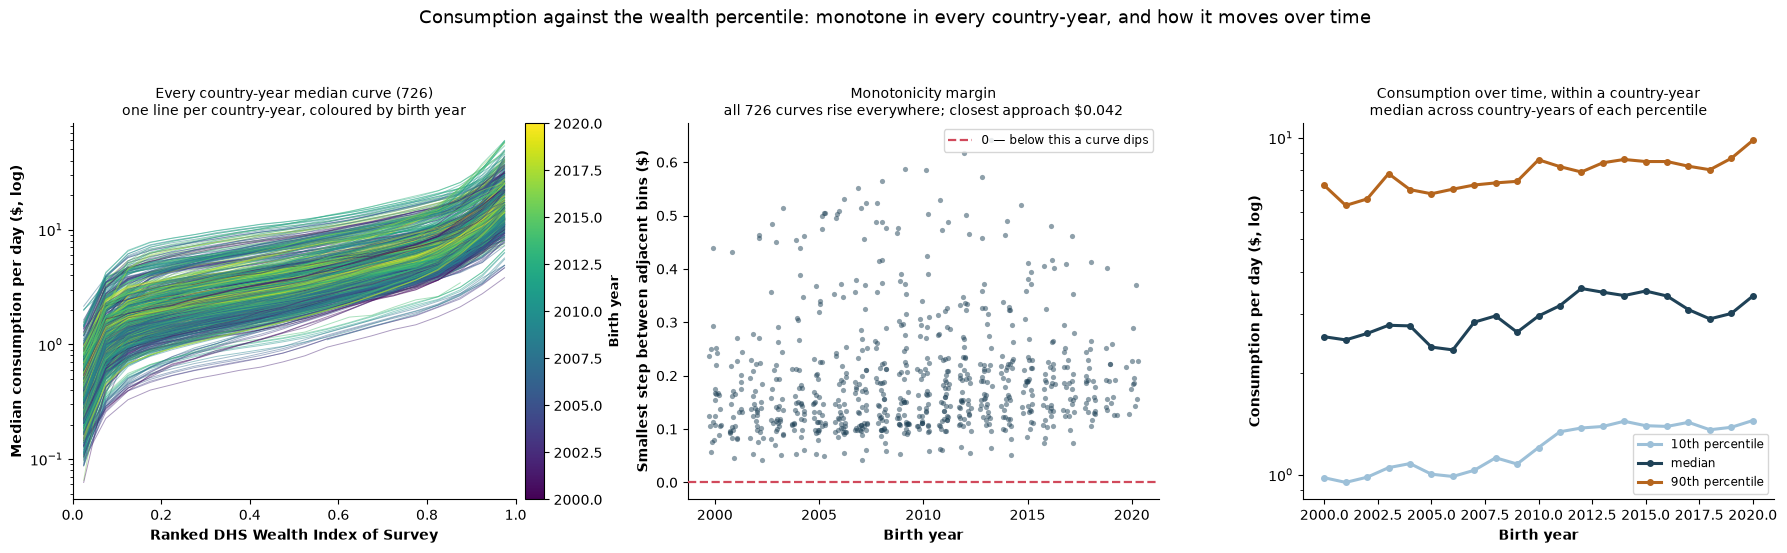


percentiles of consumption over time (median across country-years):
              p10    p50    p90  p90_over_p10
birth_year                                   
2000        0.979  2.565  7.214         7.372
2001        0.948  2.510  6.292         6.638
2002        0.982  2.623  6.579         6.697
2003        1.048  2.774  7.820         7.459
2004        1.078  2.763  7.009         6.501
2005        1.003  2.390  6.815         6.797
2006        0.987  2.345  7.033         7.125
2007        1.030  2.834  7.235         7.026
2008        1.122  2.958  7.341         6.545
2009        1.075  2.645  7.419         6.903
2010        1.203  2.956  8.597         7.146
2011        1.340  3.173  8.203         6.122
2012        1.375  3.567  7.908         5.752
2013        1.389  3.478  8.422         6.062
2014        1.440  3.399  8.616         5.984
2015        1.397  3.506  8.494         6.082
2016        1.390  3.388  8.495         6.112
2017        1.429  3.088  8.226         5.757
2018       

In [ ]:
# The same information as the 62-page PDF, in one figure #####################
# The per-country-year pages exist to show two things: that consumption rises
# monotonically with the wealth percentile, and how that relationship moves
# over time. Neither needs a page each - and the scatter behind those pages
# adds almost nothing, because the rank correlation is 0.98-1.00, so the
# points sit on the median line. Drop the scatter and a country-year becomes a
# single thin line, which means all of them fit on one axes.
#
#   left   - every country-year's median curve, coloured by birth year.
#            Monotonicity is every line rising; the time dimension is whether
#            the colours separate vertically.
#   middle - the monotonicity claim, quantified: the SMALLEST step between
#            adjacent bins in each curve. Above zero means that curve rises
#            everywhere. This is stronger than 726 black lines, because it
#            shows how much margin there is rather than just that a test
#            passed.
#   right  - the time dimension alone: the 10th, 50th and 90th percentile of
#            consumption within a country-year, summarised across countries
#            per birth year.
#
# The right panel takes the median ACROSS country-years rather than pooling
# every birth, so one large survey cannot carry a year on its own. Which
# countries are surveyed still changes year to year, so read it as a trend in
# the surveyed set, not in a fixed population.
M3_YEARS = (2000, 2020)
M3_BINS = np.linspace(0, 1, 21)
M3_MIN_BIRTHS = 25
M3_CMAP = "viridis"

_m3 = df_raw[df_raw["level"] == 3].dropna(
    subset=[
        "unweighted_population_percentile",
        "consumption_pd",
        "location_name",
        "birth_year",
    ]
)
_m3 = _m3[(_m3["consumption_pd"] > 0) & _m3["birth_year"].between(*M3_YEARS)]
_m3_keep = _m3.groupby(["location_name", "birth_year"]).size().rename("n").reset_index()
_m3_keep = _m3_keep[_m3_keep["n"] >= M3_MIN_BIRTHS]
_m3 = _m3.merge(
    _m3_keep[["location_name", "birth_year"]], on=["location_name", "birth_year"]
)

# Every country-year's median curve, in one pass #############################
_m3["_bin"] = pd.cut(
    _m3["unweighted_population_percentile"], bins=M3_BINS, include_lowest=True
)
m3_curves = (
    _m3.groupby(["location_name", "birth_year", "_bin"], observed=False)[
        "consumption_pd"
    ]
    .median()
    .unstack("_bin")
    # observed=False expands the full country x year x bin cartesian product,
    # so country-years that never happened come back as all-NaN rows. Keeping
    # them would count each one as a failed monotonicity test.
    .dropna(how="all")
)
_m3_centres = 0.5 * (M3_BINS[:-1] + M3_BINS[1:])

# Smallest step in each curve; >= 0 means it never goes down
_m3_steps = m3_curves.apply(
    lambda row: (
        np.min(np.diff(row.dropna().to_numpy())) if row.notna().sum() > 1 else np.nan
    ),
    axis=1,
).rename("smallest_step")
m3_summary = _m3_steps.reset_index()
m3_summary["monotone"] = m3_summary["smallest_step"] >= 0

# Within-country-year percentiles, for the time panel
m3_pctl = (
    _m3.groupby(["location_name", "birth_year"])["consumption_pd"]
    .quantile([0.1, 0.5, 0.9])
    .unstack()
    .rename(columns={0.1: "p10", 0.5: "p50", 0.9: "p90"})
    .reset_index()
)
m3_time = m3_pctl.groupby("birth_year")[["p10", "p50", "p90"]].median()

print(
    f"{len(m3_curves):,} country-year curves, "
    f"{m3_curves.index.get_level_values('location_name').nunique()} countries, "
    f"{M3_YEARS[0]}-{M3_YEARS[1]}\n"
    f"  monotone: {int(m3_summary['monotone'].sum()):,} of {len(m3_summary):,}\n"
    f"  smallest step anywhere: ${m3_summary['smallest_step'].min():.3f} "
    f"(a negative value would be a curve that dips)"
)

_years = m3_curves.index.get_level_values("birth_year").to_numpy()
_norm = plt.Normalize(vmin=_years.min(), vmax=_years.max())
_cmap = plt.get_cmap(M3_CMAP)

fig, axes = plt.subplots(ncols=3, figsize=(18, 5.6))

# 1. every curve, coloured by year ###########################################
ax = axes[0]
for (_, year), row in m3_curves.iterrows():
    vals = row.to_numpy(dtype=float)
    keep = np.isfinite(vals)
    ax.plot(
        _m3_centres[keep],
        vals[keep],
        color=_cmap(_norm(year)),
        lw=0.7,
        alpha=0.45,
        zorder=2,
    )
ax.set_yscale("log")
ax.set_xlim(0, 1)
ax.set_xlabel("Ranked DHS Wealth Index of Survey", fontweight="bold")
ax.set_ylabel("Median consumption per day ($, log)", fontweight="bold")
ax.set_title(
    f"Every country-year median curve ({len(m3_curves):,})\n"
    "one line per country-year, coloured by birth year",
    fontsize=10,
)
fig.colorbar(
    plt.cm.ScalarMappable(norm=_norm, cmap=_cmap), ax=ax, fraction=0.04, pad=0.02
).set_label("Birth year", fontweight="bold", fontsize=9)

# 2. the monotonicity margin #################################################
ax = axes[1]
_rng = np.random.default_rng(0)
ax.scatter(
    m3_summary["birth_year"] + _rng.uniform(-0.3, 0.3, len(m3_summary)),
    m3_summary["smallest_step"],
    s=14,
    alpha=0.5,
    color="#1f4257",
    linewidths=0,
    zorder=2,
)
ax.axhline(
    0, color="#d1495b", lw=1.6, ls="--", zorder=3, label="0 — below this a curve dips"
)
ax.set_xlabel("Birth year", fontweight="bold")
ax.set_ylabel("Smallest step between adjacent bins ($)", fontweight="bold")
ax.set_title(
    "Monotonicity margin\n"
    f"all {int(m3_summary['monotone'].sum()):,} curves rise everywhere; "
    f"closest approach ${m3_summary['smallest_step'].min():.3f}",
    fontsize=10,
)
ax.legend(fontsize=8.5, loc="upper right")

# 3. the time dimension alone ################################################
ax = axes[2]
for col, colour, label in (
    ("p10", "#9dc0d8", "10th percentile"),
    ("p50", "#1f4257", "median"),
    ("p90", "#b5651d", "90th percentile"),
):
    ax.plot(
        m3_time.index, m3_time[col], color=colour, lw=2.2, marker="o", ms=4, label=label
    )
ax.set_yscale("log")
ax.set_xlabel("Birth year", fontweight="bold")
ax.set_ylabel("Consumption per day ($, log)", fontweight="bold")
ax.set_title(
    "Consumption over time, within a country-year\n"
    "median across country-years of each percentile",
    fontsize=10,
)
ax.legend(fontsize=8.5)

for ax in axes:
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.suptitle(
    "Consumption against the wealth percentile: monotone in every country-year, "
    "and how it moves over time",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0, 1, 0.93))

plot_path = f"{PLOT_OUTPUT}consumption_percentile_monotonicity.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print("\npercentiles of consumption over time (median across country-years):")
_t = m3_time.copy()
_t["p90_over_p10"] = _t["p90"] / _t["p10"]
print(_t.round(3).to_string())
print(
    f"\nfirst to last year: p10 ${m3_time['p10'].iloc[0]:.2f} -> "
    f"${m3_time['p10'].iloc[-1]:.2f}, "
    f"p90 ${m3_time['p90'].iloc[0]:.2f} -> ${m3_time['p90'].iloc[-1]:.2f}"
)